# Stripe cleanup
This script tests removing the 100kHz electrical noise artifact from mini2p stacks. It assumes two channels interleaved with each other (red and green). If you only acquire one channel, skip the deinterleaving step. 
Steps:
- find the tiff stack in the target folder
- read the tiff header to get the image dimensions and frame nr
- load the tiff stack into a np array
- sanity check: display the average frame like FIJI would
- per channel, per frame calculate the average forward scanned line and the average reverse scanned line
- per channel, per frame subtract the average fw and rv lines from every fw and rv line in the frame respectively
- sanity check: display average of the destriped stack
- save the detrended stacks into seperate files and one interleaved file (to feed to suite2p)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image

In [ ]:
path = '/Users/sandrareinert/Library/Mobile Documents/com~apple~CloudDocs/Documents/Postdoc_SWC/Local_bits/mini2p test/stripes/MY_71_R'
tiff_files = [f for f in os.listdir(path) if f.endswith('.tif')]
selected_tiff = tiff_files[0]  # select the first tiff file for testing

In [ ]:
#read the tiff header to get the dimensions
with Image.open(os.path.join(path, selected_tiff)) as img:
    width, height = img.size
    num_frames = img.n_frames
print(f'Tiff dimensions: {width}x{height}, Number of frames: {num_frames}')

In [ ]:
#now read the tiff stack into a numpy array
tiff_stack = np.zeros((height, width, num_frames))
with Image.open(os.path.join(path, selected_tiff)) as img:
    for i in range(num_frames):
        img.seek(i)
        tiff_stack[:, :, i] = np.array(img)

In [ ]:
#deinterleave 
stack1 = tiff_stack[:, :, ::2]
stack2 = tiff_stack[:, :, 1::2]

#normalize each frame by max and min and then average them all
new_stack1 = np.zeros_like(stack1)
for i in range(stack1.shape[2]):
    new_stack1[:, :, i] = (stack1[:, :, i] - np.min(stack1[:, :, i])) / (np.max(stack1[:, :, i]) - np.min(stack1[:, :, i]))
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.nanmean(new_stack1, axis=2), cmap='gray')
new_stack2 = np.zeros_like(stack2)
for i in range(stack2.shape[2]):
    new_stack2[:, :, i] = (stack2[:, :, i] - np.min(stack2[:, :, i])) / (np.max(stack2[:, :, i]) - np.min(stack2[:, :, i]))
plt.subplot(1, 2, 2)
plt.imshow(np.nanmean(new_stack2, axis=2), cmap='gray')

In [ ]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack1 = np.zeros_like(stack1)
frame_forward = np.zeros([stack1.shape[0], stack1.shape[2]])
frame_reverse = np.zeros([stack1.shape[0], stack1.shape[2]])
for i in range(stack1.shape[2]):
    forward_lines = stack1[::2, :, i]
    reverse_lines = stack1[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    for j in range(stack1.shape[0]):
        if j % 2 == 0:
            detrended_stack1[j, :, i] = stack1[j, :, i] - avg_forward
        else:
            detrended_stack1[j, :, i] = stack1[j, :, i] - avg_reverse

plt.imshow(np.nanmean(detrended_stack1, axis=2), cmap='gray')

In [ ]:
#save this as a tiff stack
output_file = os.path.join(path, 'detrended_stack1.tiff')
with Image.fromarray(detrended_stack1[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(detrended_stack1[:, :, i]) for i in range(1, detrended_stack1.shape[2])])

In [ ]:
#subtract the forward and reverse averages from even and odd lines respectively to get a detrended stack
detrended_stack2 = np.zeros_like(stack2)
frame_forward = np.zeros([stack2.shape[0], stack2.shape[2]])
frame_reverse = np.zeros([stack2.shape[0], stack2.shape[2]])
for i in range(stack2.shape[2]):
    forward_lines = stack2[::2, :, i]
    reverse_lines = stack2[1::2, :, i]
    avg_forward = np.nanmean(forward_lines, axis=0)
    avg_reverse = np.nanmean(reverse_lines, axis=0)
    frame_forward[:, i] = avg_forward
    frame_reverse[:, i] = avg_reverse
    for j in range(stack2.shape[0]):
        if j % 2 == 0:
            detrended_stack2[j, :, i] = stack2[j, :, i] - avg_forward
        else:
            detrended_stack2[j, :, i] = stack2[j, :, i] - avg_reverse

plt.imshow(np.nanmean(detrended_stack2, axis=2), cmap='gray')

In [ ]:
#save this as a tiff stack
output_file = os.path.join(path, 'detrended_stack2.tiff')
with Image.fromarray(detrended_stack2[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(detrended_stack2[:, :, i]) for i in range(1, detrended_stack2.shape[2])])

In [ ]:
#interleave a frame from stack1 and stack2 to get a new stack with the same dimensions as the original tiff stack
interleaved_stack = np.zeros_like(tiff_stack)
interleaved_stack[:, :, ::2] = detrended_stack1
interleaved_stack[:, :, 1::2] = detrended_stack2

#save this as a tiff stack
output_file = os.path.join(path, 'detrended_interleaved_stack.tiff')
with Image.fromarray(interleaved_stack[:, :, 0]) as img:
    img.save(output_file, save_all=True, append_images=[Image.fromarray(interleaved_stack[:, :, i]) for i in range(1, interleaved_stack.shape[2])])

# Stripe cleanup (Meg + Claude)

In [ ]:
import os
import gc
import numpy as np
import tifffile
import matplotlib.pyplot as plt

path = '/Users/megyoung/Desktop/mini2p Images/72Lgoodtask'
selected_tiff = "72ltask_00001.tif"

tiff_path = os.path.join(path, selected_tiff)

# ----------------------------
# Inspect TIFF without loading whole thing
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Frames:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

# ----------------------------
# Read selected frames only
# ----------------------------
def read_pages(tiff_path, frame_indices):
    frames = []

    with tifffile.TiffFile(tiff_path) as tif:
        for idx in frame_indices:
            frames.append(tif.pages[int(idx)].asarray())

    return np.stack(frames, axis=0)

# ----------------------------
# Preview channels
# ----------------------------
def preview_channel(tiff_path, channel=0, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)

    inds = np.arange(channel, min(n_pages, channel + 2 * n_frames), 2)

    chunk = read_pages(tiff_path, inds).astype(np.float32)

    frame_min = np.min(chunk, axis=(1, 2), keepdims=True)
    frame_max = np.max(chunk, axis=(1, 2), keepdims=True)

    norm = (chunk - frame_min) / (frame_max - frame_min + 1e-8)
    mean_img = np.mean(norm, axis=0)

    del chunk, norm
    gc.collect()

    return mean_img

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(preview_channel(tiff_path, channel=0, n_frames=200), cmap="gray")
plt.title("Channel / Stack 1 preview")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(preview_channel(tiff_path, channel=1, n_frames=200), cmap="gray")
plt.title("Channel / Stack 2 preview")
plt.axis("off")

plt.show()

# ----------------------------
# Detrend one chunk
# ----------------------------
def detrend_chunk(chunk, preserve_frame_mean=True):
    """Remove odd/even line stripes without discarding fluorescence baseline.

    With preserve_frame_mean=True (recommended), only the zero-mean
    spatial variation of each odd/even line profile is subtracted. The old
    zero-centering behaviour remains available with False for comparison.
    """
    chunk = chunk.astype(np.float32)

    avg_forward = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_reverse = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)

    if preserve_frame_mean:
        # Subtract only the column-dependent stripe shape. Subtracting the
        # complete profiles zero-centres every frame and removes real global
        # calcium fluctuations as well as the positive F0 needed for dF/F.
        avg_forward = avg_forward - np.mean(avg_forward, axis=2, keepdims=True)
        avg_reverse = avg_reverse - np.mean(avg_reverse, axis=2, keepdims=True)

    destriped = np.empty_like(chunk, dtype=np.float32)
    destriped[:, ::2, :] = chunk[:, ::2, :] - avg_forward
    destriped[:, 1::2, :] = chunk[:, 1::2, :] - avg_reverse

    return destriped

# ----------------------------
# Detrend and save channel
# ----------------------------
def detrend_and_save_channel(
    tiff_path,
    channel,
    output_file,
    chunk_size=100,
    output_dtype=np.float32
):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)

        channel_frames = np.arange(channel, n_pages, 2)

        print(f"Processing channel {channel}")
        print(f"Number of frames: {len(channel_frames)}")
        print(f"Saving to: {output_file}")

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, len(channel_frames), chunk_size):
                end = min(start + chunk_size, len(channel_frames))
                inds = channel_frames[start:end]

                chunk = np.stack(
                    [tif.pages[int(idx)].asarray() for idx in inds],
                    axis=0
                )

                detrended = detrend_chunk(chunk)

                writer.write(detrended.astype(output_dtype))

                print(f"Saved frames {start} to {end} / {len(channel_frames)}")

                del chunk, detrended
                gc.collect()

    print("Done:", output_file)

# ----------------------------
# Run channel 1
# ----------------------------
output_file1 = os.path.join(path, "detrended_stack1.tiff")

detrend_and_save_channel(
    tiff_path=tiff_path,
    channel=0,
    output_file=output_file1,
    chunk_size=50,
    output_dtype=np.float32
)

# ----------------------------
# Run channel 2
# ----------------------------
output_file2 = os.path.join(path, "detrended_stack2.tiff")

detrend_and_save_channel(
    tiff_path=tiff_path,
    channel=1,
    output_file=output_file2,
    chunk_size=50,
    output_dtype=np.float32
)

# ----------------------------
# Preview saved outputs safely
# ----------------------------
def preview_saved_tiff(tiff_path, n_frames=200):
    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        inds = np.arange(0, min(n_pages, n_frames))

        chunk = np.stack(
            [tif.pages[int(idx)].asarray() for idx in inds],
            axis=0
        ).astype(np.float32)

    mean_img = np.mean(chunk, axis=0)

    del chunk
    gc.collect()

    return mean_img

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(preview_saved_tiff(output_file1, n_frames=200), cmap="gray")
plt.title("Detrended stack 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(preview_saved_tiff(output_file2, n_frames=200), cmap="gray")
plt.title("Detrended stack 2")
plt.axis("off")

plt.show()

In [ ]:
import os
import re
import gc
import numpy as np
import tifffile
import scipy.io as sio
import matlab.engine

path = '/Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-03_id-MY_71_R/ses-171_date-20260622/funcimg'
selected_tiff = "71rtask_00001.tif"
tiff_path = os.path.join(path, selected_tiff)

transform_mat = '/Volumes/behrens/meg/file_00001_TransformMatrix_Far-reaching_1.0_0514213221.mat'

# ----------------------------
# Read t-lens / Z from metadata
# ----------------------------
def read_tlens_z_from_metadata(tiff_path):
    with tifffile.TiffFile(tiff_path) as tif:
        desc = tif.pages[0].description or ""

    patterns = [
        r"SI\.hFastZ\.position\s*=\s*([-+]?\d*\.?\d+)",
        r"SI\.hFastZ\.userZs\s*=\s*([-+]?\d*\.?\d+)",
        r"SI\.hMotors\.samplePosition\s*=\s*\[.*?([-+]?\d*\.?\d+)\]",
        r"t.?lens.*?([-+]?\d*\.?\d+)",
        r"Z\s*=\s*([-+]?\d*\.?\d+)",
    ]

    for pat in patterns:
        m = re.search(pat, desc, flags=re.IGNORECASE)
        if m:
            return float(m.group(1))

    raise ValueError(
        "Could not find t-lens/Z height in metadata. "
        "Pass z_um manually."
    )


# ----------------------------
# Find nearest transform
# ----------------------------
def get_transform_index(transform_mat, z_um):
    mat = sio.loadmat(transform_mat, squeeze_me=True, struct_as_record=False)
    transforms = mat["TransfMatrix"]

    zs = np.array([float(t.Z) for t in transforms])
    idx = int(np.argmin(np.abs(zs - z_um)))

    return idx + 1, zs[idx]   # MATLAB indexing starts at 1


# ----------------------------
# Destripe / detrend chunk
# ----------------------------
def detrend_chunk(chunk, preserve_frame_mean=True):
    """
    chunk shape: frames x height x width
    """
    chunk = chunk.astype(np.float32)

    avg_forward = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_reverse = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)

    if preserve_frame_mean:
        # Preserve the positive F0 and population activity by subtracting
        # only column-dependent stripe variation. False reproduces the old
        # zero-centred output for direct comparison.
        avg_forward -= np.mean(avg_forward, axis=2, keepdims=True)
        avg_reverse -= np.mean(avg_reverse, axis=2, keepdims=True)

    detrended = np.empty_like(chunk, dtype=np.float32)
    detrended[:, ::2, :] = chunk[:, ::2, :] - avg_forward
    detrended[:, 1::2, :] = chunk[:, 1::2, :] - avg_reverse

    return detrended


# ----------------------------
# Combined destriping + distortion correction
# ----------------------------
def destripe_and_distortion_correct_channel(
    tiff_path,
    channel,
    output_file,
    transform_mat,
    z_um=None,
    chunk_size=50,
    output_dtype=np.float32,
    apply_distortion=True
):
    if z_um is None:
        z_um = read_tlens_z_from_metadata(tiff_path)

    matlab_idx, matched_z = get_transform_index(transform_mat, z_um)

    print(f"Input Z/t-lens height: {z_um}")
    print(f"Using transform #{matlab_idx}, calibrated Z = {matched_z}")

    eng = None

    if apply_distortion:
        eng = matlab.engine.start_matlab()

        eng.eval(f"S = load('{transform_mat}');", nargout=0)
        eng.eval(f"T = S.TransfMatrix{{{matlab_idx}}};", nargout=0)
        eng.eval("tform = T.Trasfm;", nargout=0)

    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        channel_frames = np.arange(channel, n_pages, 2)

        print(f"Processing channel {channel}")
        print(f"Number of frames: {len(channel_frames)}")
        print(f"Saving to: {output_file}")

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, len(channel_frames), chunk_size):
                end = min(start + chunk_size, len(channel_frames))
                inds = channel_frames[start:end]

                chunk = np.stack(
                    [tif.pages[int(idx)].asarray() for idx in inds],
                    axis=0
                )

                detrended = detrend_chunk(chunk)

                if apply_distortion:
                    corrected_frames = []

                    for frame in detrended:
                        eng.workspace["I"] = matlab.single(frame.tolist())
                        eng.eval("""
                            R = imref2d(size(I));
                            J = imwarp(I, tform, 'OutputView', R, 'FillValues', 0);
                        """, nargout=0)

                        J = np.array(eng.workspace["J"], dtype=np.float32)
                        corrected_frames.append(J)

                    out_chunk = np.stack(corrected_frames, axis=0)

                else:
                    out_chunk = detrended

                writer.write(out_chunk.astype(output_dtype))

                print(f"Saved frames {start} to {end} / {len(channel_frames)}")

                del chunk, detrended, out_chunk
                gc.collect()

    if eng is not None:
        eng.quit()

    print("Done:", output_file)


# ----------------------------
# Run channel 1
# ----------------------------
output_file1 = os.path.join(path, "stack1_destriped_distortion_corrected.tiff")

destripe_and_distortion_correct_channel(
    tiff_path=tiff_path,
    channel=0,
    output_file=output_file1,
    transform_mat=transform_mat,
    chunk_size=50,
    output_dtype=np.float32,
    apply_distortion=False,
    z_um=0,
)


# ----------------------------
# Run channel 2
# ----------------------------
output_file2 = os.path.join(path, "stack2_destriped_distortion_corrected.tiff")

destripe_and_distortion_correct_channel(
    tiff_path=tiff_path,
    channel=1,
    output_file=output_file2,
    transform_mat=transform_mat,
    chunk_size=50,
    output_dtype=np.float32,
    apply_distortion=False,
    z_um=0,
)

In [ ]:
import tifffile

with tifffile.TiffFile(tiff_path) as tif:
    desc = tif.pages[0].description

print(desc)

In [ ]:
import tifffile
import pprint

with tifffile.TiffFile(tiff_path) as tif:
    md = tif.scanimage_metadata

pprint.pp(md)

In [ ]:
eng = matlab.engine.start_matlab()

print("imref2d:", eng.eval("which('imref2d')", nargout=1))
print("imwarp:", eng.eval("which('imwarp')", nargout=1))
print("imresize:", eng.eval("which('imresize')", nargout=1))
print("image toolbox license:", eng.eval("license('test','image_toolbox')", nargout=1))

eng.quit()

In [ ]:
destripe_and_distortion_correct_channel(
    tiff_path=tiff_path,
    channel=0,
    output_file=os.path.join(path, "stack1_destriped_ONLY.tiff"),
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=50,
    output_dtype=np.float32,
    apply_distortion=False,
)

In [ ]:
import os
import re
import gc
import numpy as np
import tifffile
import scipy.io as sio
import matlab
import matlab.engine


# ----------------------------
# Paths
# ----------------------------
path = '/Volumes/behrens/meg/3x3_field_reward_bandit/rawdata/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg'
selected_tiff = "72ltask_00001.tif"
tiff_path = os.path.join(path, selected_tiff)

transform_mat = '/Volumes/behrens/meg/file_00001_TransformMatrix_Far-reaching_1.0_0514213221.mat'


# ----------------------------
# Inspect TIFF
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    n_pages = len(tif.pages)
    height, width = tif.pages[0].shape
    dtype = tif.pages[0].dtype

print("Frames/pages:", n_pages)
print("Height:", height)
print("Width:", width)
print("dtype:", dtype)


# ----------------------------
# Metadata t-lens reader
# ----------------------------
def read_tlens_z_from_metadata(tiff_path):
    """
    For your file, this will likely return SI.hFastZ.position = 0.
    Do NOT use SI.hMotors.samplePosition for the distortion transform.
    """
    with tifffile.TiffFile(tiff_path) as tif:
        md = tif.scanimage_metadata["FrameData"]

    keys = [
        "SI.hFastZ.position",
        "SI.hStackManager.zsRelative",
    ]

    for key in keys:
        if key in md:
            return float(md[key])

    raise ValueError(
        "Could not find t-lens/FastZ height. "
        "Pass z_um manually."
    )


# ----------------------------
# Transform helpers
# ----------------------------
def get_available_transform_zs(transform_mat):
    mat = sio.loadmat(transform_mat, squeeze_me=True, struct_as_record=False)
    transforms = mat["TransfMatrix"]

    zs = []
    for t in transforms:
        try:
            zs.append(float(t.Z))
        except Exception:
            pass

    return zs


def get_transform_index(transform_mat, z_um):
    """
    Returns MATLAB 1-indexed transform index and matched calibrated Z.
    """
    zs = np.array(get_available_transform_zs(transform_mat), dtype=float)

    if len(zs) == 0:
        raise ValueError("Could not read any Z values from transform matrix.")

    idx = int(np.argmin(np.abs(zs - z_um)))

    return idx + 1, zs[idx]


# ----------------------------
# Destriping / detrending
# ----------------------------
def detrend_chunk(chunk, preserve_frame_mean=True):
    """
    chunk shape: frames x height x width

    This subtracts the average even-line profile from even lines
    and average odd-line profile from odd lines.
    """
    chunk = chunk.astype(np.float32)

    avg_forward = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_reverse = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)

    if preserve_frame_mean:
        # Preserve the positive F0 and population activity by subtracting
        # only column-dependent stripe variation. False reproduces the old
        # zero-centred output for direct comparison.
        avg_forward -= np.mean(avg_forward, axis=2, keepdims=True)
        avg_reverse -= np.mean(avg_reverse, axis=2, keepdims=True)

    detrended = np.empty_like(chunk, dtype=np.float32)
    detrended[:, ::2, :] = chunk[:, ::2, :] - avg_forward
    detrended[:, 1::2, :] = chunk[:, 1::2, :] - avg_reverse

    return detrended


# ----------------------------
# MATLAB setup
# ----------------------------
def start_matlab_with_transform(transform_mat, z_um):
    matlab_idx, matched_z = get_transform_index(transform_mat, z_um)

    print(f"Input t-lens/FastZ height: {z_um}")
    print(f"Using transform #{matlab_idx}, calibrated Z = {matched_z}")

    eng = matlab.engine.start_matlab()

    eng.eval(f"S = load('{transform_mat}');", nargout=0)

    # Your .mat loads as a cell array in MATLAB
    eng.eval(f"T = S.TransfMatrix{{{matlab_idx}}};", nargout=0)
    eng.eval("tform = T.Trasfm;", nargout=0)

    return eng, matlab_idx, matched_z


# ----------------------------
# Distortion correction for one frame
# ----------------------------
def matlab_warp_one_frame(eng, frame):
    """
    Applies MATLAB tform to one frame.
    Requires Image Processing Toolbox for imref2d + imwarp.
    """
    frame = frame.astype(np.float32)

    eng.workspace["I"] = matlab.single(frame.tolist())

    eng.eval("""
        R = imref2d(size(I));
        J = imwarp(I, tform, 'OutputView', R, 'FillValues', 0);
    """, nargout=0)

    J = np.array(eng.workspace["J"], dtype=np.float32)

    if J.shape != frame.shape:
        raise RuntimeError(
            f"Warped frame has wrong shape. Input {frame.shape}, output {J.shape}"
        )

    return J


# ----------------------------
# Safe TIFF writing
# ----------------------------
def write_frames_safely(writer, out_chunk, output_dtype=np.float32):
    """
    Writes one frame at a time. Safer for Fiji than writing whole chunks.
    """
    for frame in out_chunk:
        writer.write(
            frame.astype(output_dtype),
            contiguous=False
        )


# ----------------------------
# Main processing function
# ----------------------------
def destripe_and_distortion_correct_channel(
    tiff_path,
    channel,
    output_file,
    transform_mat,
    z_um=None,
    chunk_size=20,
    output_dtype=np.float32,
    apply_distortion=True,
    max_frames=None
):
    if z_um is None:
        z_um = read_tlens_z_from_metadata(tiff_path)

    if os.path.exists(output_file):
        os.remove(output_file)

    eng = None

    if apply_distortion:
        eng, matlab_idx, matched_z = start_matlab_with_transform(transform_mat, z_um)

    frames_written = 0

    try:
        with tifffile.TiffFile(tiff_path) as tif:
            n_pages = len(tif.pages)
            channel_frames = np.arange(channel, n_pages, 2)

            if max_frames is not None:
                channel_frames = channel_frames[:max_frames]

            print(f"Processing channel {channel}")
            print(f"Number of frames: {len(channel_frames)}")
            print(f"Saving to: {output_file}")

            with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
                for start in range(0, len(channel_frames), chunk_size):
                    end = min(start + chunk_size, len(channel_frames))
                    inds = channel_frames[start:end]

                    chunk = np.stack(
                        [tif.pages[int(idx)].asarray() for idx in inds],
                        axis=0
                    )

                    detrended = detrend_chunk(chunk)

                    if apply_distortion:
                        corrected_frames = []

                        for i, frame in enumerate(detrended):
                            J = matlab_warp_one_frame(eng, frame)
                            corrected_frames.append(J)

                        out_chunk = np.stack(corrected_frames, axis=0)

                    else:
                        out_chunk = detrended

                    write_frames_safely(
                        writer,
                        out_chunk,
                        output_dtype=output_dtype
                    )

                    frames_written += out_chunk.shape[0]

                    print(
                        f"Saved frames {start} to {end} / {len(channel_frames)}"
                    )

                    del chunk, detrended, out_chunk
                    gc.collect()

    finally:
        if eng is not None:
            eng.quit()

    file_size = os.path.getsize(output_file) if os.path.exists(output_file) else 0

    print("Done:", output_file)
    print("Frames written:", frames_written)
    print("Output size bytes:", file_size)

    if frames_written == 0 or file_size < 1000:
        raise RuntimeError(
            f"Output file looks empty or invalid: {output_file}. "
            f"Frames written = {frames_written}, size = {file_size} bytes."
        )

In [ ]:
# ----------------------------
# Run channel 1
# ----------------------------
output_file1 = os.path.join(path, "stack1_destriped_distortion_corrected.tiff")

destripe_and_distortion_correct_channel(
    tiff_path=tiff_path,
    channel=0,
    output_file=output_file1,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=10,
    output_dtype=np.float32,
    apply_distortion=True,
)


# ----------------------------
# Run channel 2
# ----------------------------
output_file2 = os.path.join(path, "stack2_destriped_distortion_corrected.tiff")

destripe_and_distortion_correct_channel(
    tiff_path=tiff_path,
    channel=1,
    output_file=output_file2,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=10,
    output_dtype=np.float32,
    apply_distortion=True,
)

In [ ]:
import matplotlib.pyplot as plt

# Pick one frame from channel 0
with tifffile.TiffFile(tiff_path) as tif:
    raw_frame = tif.pages[0].asarray().astype(np.float32)

# Destripe one frame
destriped_frame = detrend_chunk(raw_frame[None, :, :])[0]

# Start MATLAB and load transform
eng, matlab_idx, matched_z = start_matlab_with_transform(
    transform_mat=transform_mat,
    z_um=0
)

# Apply distortion correction
corrected_frame = matlab_warp_one_frame(eng, destriped_frame)

eng.quit()

print("Raw:", raw_frame.shape, raw_frame.dtype, np.min(raw_frame), np.max(raw_frame))
print("Destriped:", destriped_frame.shape, destriped_frame.dtype, np.min(destriped_frame), np.max(destriped_frame))
print("Corrected:", corrected_frame.shape, corrected_frame.dtype, np.min(corrected_frame), np.max(corrected_frame))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(raw_frame, cmap="gray")
plt.title("Raw frame")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(destriped_frame, cmap="gray")
plt.title("Destriped frame")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(corrected_frame, cmap="gray")
plt.title("Destriped + distortion corrected")
plt.axis("off")

plt.show()

In [ ]:
import os
import numpy as np
import scipy.io as sio
import tifffile
import matplotlib.pyplot as plt
from skimage.transform import PiecewiseAffineTransform, warp


# ----------------------------
# Paths
# ----------------------------

# ----------------------------
# Destriping
# ----------------------------
def detrend_chunk(chunk, preserve_frame_mean=True):
    chunk = chunk.astype(np.float32)

    avg_forward = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_reverse = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)

    if preserve_frame_mean:
        # Preserve the positive F0 and population activity by subtracting
        # only column-dependent stripe variation. False reproduces the old
        # zero-centred output for direct comparison.
        avg_forward -= np.mean(avg_forward, axis=2, keepdims=True)
        avg_reverse -= np.mean(avg_reverse, axis=2, keepdims=True)

    detrended = np.empty_like(chunk, dtype=np.float32)
    detrended[:, ::2, :] = chunk[:, ::2, :] - avg_forward
    detrended[:, 1::2, :] = chunk[:, 1::2, :] - avg_reverse

    return detrended


# ----------------------------
# Load transform using control points
# ----------------------------
def load_piecewise_transform(transform_mat, z_um=0):
    mat = sio.loadmat(transform_mat, squeeze_me=True, struct_as_record=False)
    transforms = mat["TransfMatrix"]

    zs = np.array([float(t.Z) for t in transforms])
    idx = int(np.argmin(np.abs(zs - z_um)))

    T = transforms[idx]
    gp = T.GridParameter

    fixed = np.asarray(gp.Anchor_pairs_nodistortion, dtype=np.float32)
    moving = np.asarray(gp.Anchor_pairs_withdistortion, dtype=np.float32)

    print(f"Requested Z: {z_um}")
    print(f"Using transform index: {idx}")
    print(f"Matched Z: {zs[idx]}")
    print("Fixed points:", fixed.shape)
    print("Moving points:", moving.shape)

    # skimage expects coordinates as x, y
    # Estimate transform mapping distorted image coordinates -> corrected coordinates
    tform = PiecewiseAffineTransform()
    tform.estimate(src=moving, dst=fixed)

    return tform


# ----------------------------
# Apply correction
# ----------------------------
def apply_piecewise_correction(frame, tform):
    corrected = warp(
        frame,
        inverse_map=tform.inverse,
        output_shape=frame.shape,
        preserve_range=True,
        mode="constant",
        cval=0,
        order=1
    )

    return corrected.astype(np.float32)


# ----------------------------
# One-frame test
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    raw_frame = tif.pages[0].asarray().astype(np.float32)

destriped_frame = detrend_chunk(raw_frame[None, :, :])[0]

tform = load_piecewise_transform(transform_mat, z_um=0)

corrected_frame = apply_piecewise_correction(destriped_frame, tform)

print("Raw:", raw_frame.shape, raw_frame.min(), raw_frame.max())
print("Destriped:", destriped_frame.shape, destriped_frame.min(), destriped_frame.max())
print("Corrected:", corrected_frame.shape, corrected_frame.min(), corrected_frame.max())

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(raw_frame, cmap="gray")
plt.title("Raw")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(destriped_frame, cmap="gray")
plt.title("Destriped")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(corrected_frame, cmap="gray")
plt.title("Destriped + distortion corrected")
plt.axis("off")

plt.show()

In [ ]:
from scipy.ndimage import map_coordinates


def make_warp_maps(tform, image_shape):
    """
    Precompute source pixel coordinates once.
    """
    h, w = image_shape

    rr, cc = np.meshgrid(
        np.arange(h),
        np.arange(w),
        indexing="ij"
    )

    coords = np.column_stack([cc.ravel(), rr.ravel()])  # x, y

    src = tform.inverse(coords)

    map_x = src[:, 0].reshape(h, w).astype(np.float32)
    map_y = src[:, 1].reshape(h, w).astype(np.float32)

    return map_y, map_x


def apply_piecewise_correction_fast(frame, map_y, map_x):
    corrected = map_coordinates(
        frame.astype(np.float32),
        [map_y, map_x],
        order=1,
        mode="constant",
        cval=0
    )

    return corrected.astype(np.float32)

In [ ]:
import gc


def destripe_and_correct_channel_python(
    tiff_path,
    channel,
    output_file,
    transform_mat,
    z_um=0,
    chunk_size=20,
    output_dtype=np.float32,
    max_frames=None
):
    if os.path.exists(output_file):
        os.remove(output_file)

    tform = load_piecewise_transform(transform_mat, z_um=z_um)

    frames_written = 0

    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)
        channel_frames = np.arange(channel, n_pages, 2)

        if max_frames is not None:
            channel_frames = channel_frames[:max_frames]

        print(f"Processing channel {channel}")
        print(f"Frames to process: {len(channel_frames)}")
        print(f"Saving to: {output_file}")

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, len(channel_frames), chunk_size):
                end = min(start + chunk_size, len(channel_frames))
                inds = channel_frames[start:end]

                chunk = np.stack(
                    [tif.pages[int(idx)].asarray() for idx in inds],
                    axis=0
                )

                destriped = detrend_chunk(chunk)

                for frame in destriped:
                    corrected = apply_piecewise_correction(frame, tform)
                    writer.write(corrected.astype(output_dtype), contiguous=False)
                    frames_written += 1

                print(f"Saved frames {start} to {end} / {len(channel_frames)}")

                del chunk, destriped
                gc.collect()

    print("Done:", output_file)
    print("Frames written:", frames_written)
    print("File size:", os.path.getsize(output_file), "bytes")


# Test first with 20 frames
test_output = os.path.join(path, "TEST_stack1_20frames_destriped_distortion_corrected.tiff")

destripe_and_correct_channel_python(
    tiff_path=tiff_path,
    channel=0,
    output_file=test_output,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=5,
    output_dtype=np.float32,
    max_frames=20
)

In [1]:
import os
import gc
import numpy as np
import scipy.io as sio
import tifffile
import matplotlib.pyplot as plt

from skimage.transform import PiecewiseAffineTransform
from scipy.ndimage import map_coordinates


# ----------------------------
# Paths
# ----------------------------
# path = '/Volumes/behrens/meg/3x3_field_reward_bandit/rawdata/cohort-01/sub-05_id-MY_72_L/ses-169_date-20260621/funcimg'
path = '/Users/megyoung/Desktop/mfh lab meeting/ex1/'
selected_tiff = "pretask_00003.tif"
#path = '/Volumes/behrens/meg/3x3_field_reward_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg'
#selected_tiff = "71rtask_00001.tif"
tiff_path = os.path.join(path, selected_tiff)

transform_mat = '/Volumes/behrens/meg/file_00001_TransformMatrix_Far-reaching_1.0_0514213221.mat'


# ----------------------------
# Inspect TIFF
# ----------------------------
with tifffile.TiffFile(tiff_path) as tif:
    page0 = tif.pages[0]
    height, width = page0.shape
    dtype = page0.dtype

print("Height:", height)
print("Width:", width)
print("dtype:", dtype)

# ----------------------------
# Destriping
# ----------------------------
def detrend_chunk(chunk, preserve_frame_mean=True):
    """
    chunk shape: frames x height x width
    """
    chunk = chunk.astype(np.float32)

    avg_forward = np.mean(chunk[:, ::2, :], axis=1, keepdims=True)
    avg_reverse = np.mean(chunk[:, 1::2, :], axis=1, keepdims=True)

    if preserve_frame_mean:
        # Preserve the positive F0 and population activity by subtracting
        # only column-dependent stripe variation. False reproduces the old
        # zero-centred output for direct comparison.
        avg_forward -= np.mean(avg_forward, axis=2, keepdims=True)
        avg_reverse -= np.mean(avg_reverse, axis=2, keepdims=True)

    detrended = np.empty_like(chunk, dtype=np.float32)
    detrended[:, ::2, :] = chunk[:, ::2, :] - avg_forward
    detrended[:, 1::2, :] = chunk[:, 1::2, :] - avg_reverse

    return detrended


# ----------------------------
# Load piecewise transform
# ----------------------------
def load_piecewise_transform(transform_mat, z_um=0):
    mat = sio.loadmat(transform_mat, squeeze_me=True, struct_as_record=False)
    transforms = mat["TransfMatrix"]

    zs = np.array([float(t.Z) for t in transforms])
    idx = int(np.argmin(np.abs(zs - z_um)))

    T = transforms[idx]
    gp = T.GridParameter

    fixed = np.asarray(gp.Anchor_pairs_nodistortion, dtype=np.float32)
    moving = np.asarray(gp.Anchor_pairs_withdistortion, dtype=np.float32)

    print(f"Requested Z: {z_um}")
    print(f"Using transform index: {idx}")
    print(f"Matched Z: {zs[idx]}")
    print("Fixed points:", fixed.shape)
    print("Moving points:", moving.shape)

    tform = PiecewiseAffineTransform()
    ok = tform.estimate(src=moving, dst=fixed)

    if not ok:
        raise RuntimeError("Piecewise affine transform estimation failed.")

    return tform


# ----------------------------
# Precompute warp maps once
# ----------------------------
def make_warp_maps(tform, image_shape):
    h, w = image_shape

    rr, cc = np.meshgrid(
        np.arange(h),
        np.arange(w),
        indexing="ij"
    )

    coords = np.column_stack([cc.ravel(), rr.ravel()])  # x, y
    src = tform.inverse(coords)

    map_x = src[:, 0].reshape(h, w).astype(np.float32)
    map_y = src[:, 1].reshape(h, w).astype(np.float32)

    return map_y, map_x


# ----------------------------
# Fast correction using precomputed maps
# ----------------------------
def apply_piecewise_correction_fast(frame, map_y, map_x):
    corrected = map_coordinates(
        frame.astype(np.float32),
        [map_y, map_x],
        order=1,
        mode="constant",
        cval=0
    )

    return corrected.astype(np.float32)


# ----------------------------
# Preview one frame
# ----------------------------
def test_one_frame(
    tiff_path,
    transform_mat,
    channel=0,
    frame_number_in_channel=0,
    z_um=0
):
    page_idx = channel + 2 * frame_number_in_channel

    with tifffile.TiffFile(tiff_path) as tif:
        raw_frame = tif.pages[page_idx].asarray().astype(np.float32)

    destriped_frame = detrend_chunk(raw_frame[None, :, :])[0]

    tform = load_piecewise_transform(transform_mat, z_um=z_um)
    map_y, map_x = make_warp_maps(tform, raw_frame.shape)

    corrected_frame = apply_piecewise_correction_fast(
        destriped_frame,
        map_y,
        map_x
    )

    print("Raw:", raw_frame.shape, raw_frame.min(), raw_frame.max())
    print("Destriped:", destriped_frame.shape, destriped_frame.min(), destriped_frame.max())
    print("Corrected:", corrected_frame.shape, corrected_frame.min(), corrected_frame.max())

    plt.figure(figsize=(15, 5))

    def show_autoscaled(ax, img, title, cmap="gray", p_low=1, p_high=99.8):
        vmin, vmax = np.percentile(img[np.isfinite(img)], [p_low, p_high])
        ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(f"{title}\nmin={vmin:.1f}, max={vmax:.1f}")
        ax.axis("off")


    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    show_autoscaled(axes[0], raw_frame, "Raw")
    show_autoscaled(axes[1], destriped_frame, "Destriped")
    show_autoscaled(axes[2], corrected_frame, "Destriped + corrected")

    plt.tight_layout()
    plt.show()

    plt.show()

    return raw_frame, destriped_frame, corrected_frame


# ----------------------------
# Full stack processing
# ----------------------------
def destripe_and_correct_channel_python_fast(
    tiff_path,
    channel,
    output_file,
    transform_mat,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float32,
    max_frames=None
):
    if os.path.exists(output_file):
        os.remove(output_file)

    tform = load_piecewise_transform(transform_mat, z_um=z_um)

    with tifffile.TiffFile(tiff_path) as tif:
        frame_shape = tif.pages[0].shape
        map_y, map_x = make_warp_maps(tform, frame_shape)

        n_pages = len(tif.pages)
        channel_frames = np.arange(channel, n_pages, 2)

        if max_frames is not None:
            channel_frames = channel_frames[:max_frames]

        print(f"Processing channel {channel}")
        print(f"Frames to process: {len(channel_frames)}")
        print(f"Saving to: {output_file}")

        frames_written = 0

        with tifffile.TiffWriter(output_file, bigtiff=True) as writer:
            for start in range(0, len(channel_frames), chunk_size):
                end = min(start + chunk_size, len(channel_frames))
                inds = channel_frames[start:end]

                chunk = np.stack(
                    [tif.pages[int(idx)].asarray() for idx in inds],
                    axis=0
                )

                destriped = detrend_chunk(chunk)

                for frame in destriped:
                    corrected = apply_piecewise_correction_fast(
                        frame,
                        map_y,
                        map_x
                    )

                    writer.write(
                        corrected.astype(output_dtype),
                        contiguous=False
                    )

                    frames_written += 1

                print(f"Saved frames {start} to {end} / {len(channel_frames)}")

                del chunk, destriped
                gc.collect()

    print("Done:", output_file)
    print("Frames written:", frames_written)
    print("File size:", os.path.getsize(output_file), "bytes")

def destripe_and_correct_two_channels_interleaved(
    tiff_path,
    output_file,
    transform_mat=None,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float32,
    max_frames=None,
    apply_distortion_correction=True,
):
    """
    Process a two-channel TIFF with interleaved pages:

        page 0 = channel 1, frame 0
        page 1 = channel 2, frame 0
        page 2 = channel 1, frame 1
        page 3 = channel 2, frame 1

    When apply_distortion_correction=False, both channels are
    destriped but are not spatially warped.

    The output preserves the same interleaved order.
    """

    if os.path.exists(output_file):
        os.remove(output_file)

    tform = None
    map_y = None
    map_x = None

    if apply_distortion_correction:
        if transform_mat is None:
            raise ValueError(
                "transform_mat must be supplied when "
                "apply_distortion_correction=True."
            )

        tform = load_piecewise_transform(
            transform_mat,
            z_um=z_um,
        )

    with tifffile.TiffFile(tiff_path) as tif:
        n_pages = len(tif.pages)

        if n_pages % 2 != 0:
            raise ValueError(
                f"The TIFF contains {n_pages} pages, "
                "which is not divisible by 2."
            )

        frame_shape = tif.pages[0].shape

        if apply_distortion_correction:
            map_y, map_x = make_warp_maps(
                tform,
                frame_shape,
            )

        n_timepoints = n_pages // 2

        if max_frames is not None:
            n_timepoints = min(
                n_timepoints,
                max_frames,
            )

        print("Input:", tiff_path)
        print("Output:", output_file)
        print("Image shape:", frame_shape)
        print("Timepoints:", n_timepoints)
        print("Pages to write:", n_timepoints * 2)
        print(
            "Distortion correction:",
            apply_distortion_correction,
        )

        pages_written = 0

        with tifffile.TiffWriter(
            output_file,
            bigtiff=True,
        ) as writer:

            for start in range(
                0,
                n_timepoints,
                chunk_size,
            ):
                end = min(
                    start + chunk_size,
                    n_timepoints,
                )

                ch1_indices = 2 * np.arange(start, end)
                ch2_indices = ch1_indices + 1

                ch1_chunk = np.stack(
                    [
                        tif.pages[int(idx)].asarray()
                        for idx in ch1_indices
                    ],
                    axis=0,
                )

                ch2_chunk = np.stack(
                    [
                        tif.pages[int(idx)].asarray()
                        for idx in ch2_indices
                    ],
                    axis=0,
                )

                ch1_destriped = detrend_chunk(ch1_chunk)
                ch2_destriped = detrend_chunk(ch2_chunk)

                for i in range(end - start):
                    if apply_distortion_correction:
                        ch1_output = (
                            apply_piecewise_correction_fast(
                                ch1_destriped[i],
                                map_y,
                                map_x,
                            )
                        )

                        ch2_output = (
                            apply_piecewise_correction_fast(
                                ch2_destriped[i],
                                map_y,
                                map_x,
                            )
                        )

                    else:
                        ch1_output = ch1_destriped[i]
                        ch2_output = ch2_destriped[i]

                    writer.write(
                        ch1_output.astype(output_dtype),
                        contiguous=False,
                    )

                    writer.write(
                        ch2_output.astype(output_dtype),
                        contiguous=False,
                    )

                    pages_written += 2

                print(
                    f"Saved timepoints {start} to {end} "
                    f"/ {n_timepoints}"
                )

                del (
                    ch1_chunk,
                    ch2_chunk,
                    ch1_destriped,
                    ch2_destriped,
                )

                gc.collect()

    print("Done:", output_file)
    print("Pages written:", pages_written)
    print(
        "File size:",
        os.path.getsize(output_file),
        "bytes",
    )

Height: 512
Width: 512
dtype: int16


Requested Z: 0
Using transform index: 0
Matched Z: 0.0
Fixed points: (323, 2)
Moving points: (323, 2)


/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_87847/2664885237.py:86: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `PiecewiseAffineTransform.from_estimate` class constructor instead.
  ok = tform.estimate(src=moving, dst=fixed)


Raw: (512, 512) -200.0 2971.0
Destriped: (512, 512) -212.7661 2963.6284
Corrected: (512, 512) -171.83258 2359.45


<Figure size 1500x500 with 0 Axes>

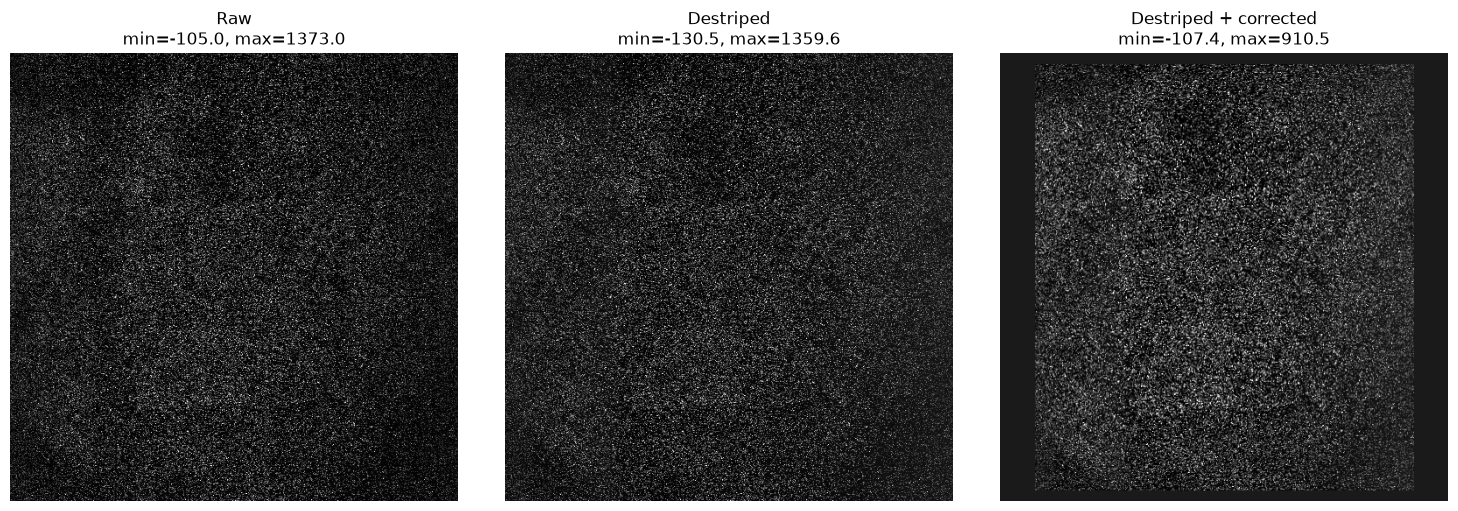

In [2]:
# ----------------------------
# 1. Test one frame first
# ----------------------------
raw_frame, destriped_frame, corrected_frame = test_one_frame(
    tiff_path=tiff_path,
    transform_mat=transform_mat,
    channel=0,
    frame_number_in_channel=50,
    z_um=0
)

In [14]:
# ----------------------------
# 2. Test 20 frames
# ----------------------------
test_output = os.path.join(
    path,
    "TEST_stack2_20frames_FAST_destriped_distortion_corrected.tiff"
)

destripe_and_correct_channel_python_fast(
    tiff_path=tiff_path,
    channel=1,
    output_file=test_output,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=20,
    output_dtype=np.float32,
    max_frames=20
)

Requested Z: 0
Using transform index: 0
Matched Z: 0.0
Fixed points: (323, 2)
Moving points: (323, 2)


/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_3331/102525139.py:76: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `PiecewiseAffineTransform.from_estimate` class constructor instead.
  ok = tform.estimate(src=moving, dst=fixed)


Processing channel 1
Frames to process: 20
Saving to: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-05_id-MY_72_L/ses-171_date-20260622/funcimg/TEST_stack2_20frames_FAST_destriped_distortion_corrected.tiff
Saved frames 0 to 20 / 20
Done: /Volumes/behrens/meg/3x3_field_blocked_reward_bandit/cohort-01/rawdata/sub-05_id-MY_72_L/ses-171_date-20260622/funcimg/TEST_stack2_20frames_FAST_destriped_distortion_corrected.tiff
Frames written: 20
File size: 20978896 bytes


In [5]:
# ----------------------------
# 3. Full interleaved channnels
# ----------------------------
output_file1 = os.path.join(
    path,
    "stack_destriped_distortion_uncorrected.tiff"
)

destripe_and_correct_two_channels_interleaved(
    tiff_path=tiff_path,
    output_file=output_file1,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float16,
    apply_distortion_correction=False
)

Input: /Users/megyoung/Desktop/72logstack/72ltask_00001.tif
Output: /Users/megyoung/Desktop/72logstack/stack_destriped_distortion_uncorrected.tiff
Image shape: (512, 512)
Timepoints: 12019
Pages to write: 24038
Distortion correction: False
Saved timepoints 0 to 100 / 12019
Saved timepoints 100 to 200 / 12019
Saved timepoints 200 to 300 / 12019
Saved timepoints 300 to 400 / 12019
Saved timepoints 400 to 500 / 12019
Saved timepoints 500 to 600 / 12019
Saved timepoints 600 to 700 / 12019
Saved timepoints 700 to 800 / 12019
Saved timepoints 800 to 900 / 12019
Saved timepoints 900 to 1000 / 12019
Saved timepoints 1000 to 1100 / 12019
Saved timepoints 1100 to 1200 / 12019
Saved timepoints 1200 to 1300 / 12019
Saved timepoints 1300 to 1400 / 12019
Saved timepoints 1400 to 1500 / 12019
Saved timepoints 1500 to 1600 / 12019
Saved timepoints 1600 to 1700 / 12019
Saved timepoints 1700 to 1800 / 12019
Saved timepoints 1800 to 1900 / 12019
Saved timepoints 1900 to 2000 / 12019
Saved timepoints 2000

In [10]:
# ----------------------------
# 4. Full channel 2
# ----------------------------
output_file2 = os.path.join(
    path,
    "72ltask_00001_channel2_destriped_undistorted.tiff"
)

destripe_and_correct_channel_python_fast(
    tiff_path=tiff_path,
    channel=1,
    output_file=output_file2,
    transform_mat=transform_mat,
    z_um=0,
    chunk_size=100,
    output_dtype=np.float16
)

Requested Z: 0
Using transform index: 0
Matched Z: 0.0
Fixed points: (323, 2)
Moving points: (323, 2)


/var/folders/g7/dhg2tq9173j2cwmlq6jvq28r0000gn/T/ipykernel_1913/1783072168.py:76: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `PiecewiseAffineTransform.from_estimate` class constructor instead.
  ok = tform.estimate(src=moving, dst=fixed)


Processing channel 1
Frames to process: 14001
Saving to: /Volumes/behrens/meg/3x3_field_reward_bandit/rawdata/cohort-01/sub-03_id-MY_71_R/ses-177_date-20260624/funcimg/72ltask_00001_channel2_destriped_undistorted.tiff
Saved frames 0 to 100 / 14001
Saved frames 100 to 200 / 14001
Saved frames 200 to 300 / 14001
Saved frames 300 to 400 / 14001
Saved frames 400 to 500 / 14001
Saved frames 500 to 600 / 14001
Saved frames 600 to 700 / 14001
Saved frames 700 to 800 / 14001
Saved frames 800 to 900 / 14001
Saved frames 900 to 1000 / 14001
Saved frames 1000 to 1100 / 14001
Saved frames 1100 to 1200 / 14001
Saved frames 1200 to 1300 / 14001
Saved frames 1300 to 1400 / 14001
Saved frames 1400 to 1500 / 14001
Saved frames 1500 to 1600 / 14001
Saved frames 1600 to 1700 / 14001
Saved frames 1700 to 1800 / 14001
Saved frames 1800 to 1900 / 14001
Saved frames 1900 to 2000 / 14001
Saved frames 2000 to 2100 / 14001
Saved frames 2100 to 2200 / 14001
Saved frames 2200 to 2300 / 14001
Saved frames 2300 to 